# Which simple rule forecasts the Diwali 2025 week best?

**Week 4, Friday, chapter 1 of 3.** Flipkart's Lucknow fulfilment centre has 104
weeks of outbound shipments and the planner must book packer shifts for the eight
festive weeks beginning 12 October 2026. The vendor curve promises 22 percent above
last year and finance's rule says 4 percent above, eighteen points apart. Before any
model earns the plan, three simple rules get a hearing: naive, same-week-last-year
and festival-aligned.

**Who needs the answer.** The FC planner, who has to pick one forecast and defend
it, and the regional operations head, who signs the shift plan. A forecast off by
10 percent in the Diwali week is a staffing miss nobody can fix on the day.

**The questions on the way.**

1. What shape do the 104 weeks have, read off a glance at the twelve rows around
   each Diwali?
2. What is the shipment the Diwali 2025 week carries, and which week carries the
   peak?
3. How do naive, same-week-last-year and festival-aligned forecast the Diwali 2025
   week?
4. Which rule lands closest to the actual shipment, and why?

Illustrative case: the company is real, the situation and the data are synthetic,
built for this class. The 104-week series is generated by `make_data_INTERNAL.py`
with a fixed seed; the numbers below come from that generator.

**Setup.** Load the shared helper `c2kit` and read the twelve-row table.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd

twelve = pd.read_csv(kit.data_dir() / "C2_W04_D05_twelve_rows_STUDENT.csv")
twelve["week_start"] = pd.to_datetime(twelve["week_start"])
twelve

,week_start,shipments
0,2024-10-07,313600
1,2024-10-14,400600
2,2024-10-21,356800
3,2024-10-28,296400
4,2024-11-04,186300
5,2024-11-11,204500
6,2025-09-29,331500
7,2025-10-06,419000
8,2025-10-13,371400
9,2025-10-20,309500


The chapter runs in four steps.

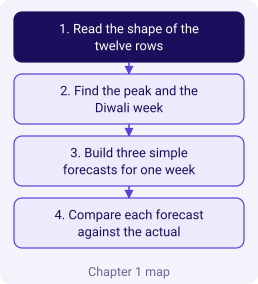

In [2]:
# MAP: the four questions the chapter answers.
kit.ladder(["Read the shape of the twelve rows",
            "Find the peak and the Diwali week",
            "Build three simple forecasts for one week",
            "Compare each forecast against the actual"], lit=0,
           title="Chapter 1 map")

## What shape do the twelve rows have around each Diwali?

The table carries six weeks around Diwali 2024 and six around Diwali 2025. Read
down each half: the shipments climb for three weeks, peak, and then drop for the
two weeks after the festival. The peak is not on the Diwali week itself; it sits
two weeks earlier, when parcels are still being shipped to arrive before the
festival.

**Predict before you run.** Which week carries the biggest shipment in each year?

a) The Diwali week itself (Mon 28 Oct 2024, Mon 20 Oct 2025).
b) The week before Diwali.
c) Two weeks before Diwali.
d) Three weeks before Diwali.

In [3]:
tw = twelve.copy()
# Mark the Diwali weeks and the two weeks before.
from datetime import date
tw["label"] = tw["week_start"].dt.strftime("%d %b %Y")
peak = tw.loc[tw["shipments"].idxmax()]
print("Biggest shipment:", peak["label"], "with", f"{int(peak['shipments']):,}", "shipments")
print()
for d in [(date(2024, 10, 28), "Diwali 2024 week"), (date(2024, 10, 14), "2 weeks before Diwali 2024"),
          (date(2025, 10, 20), "Diwali 2025 week"), (date(2025, 10, 6), "2 weeks before Diwali 2025")]:
    row = tw[tw["week_start"] == pd.Timestamp(d[0])].iloc[0]
    print(f"{d[1]:35s} ({row['label']}): {int(row['shipments']):,}")

Biggest shipment: 06 Oct 2025 with 419,000 shipments

Diwali 2024 week                    (28 Oct 2024): 296,400
2 weeks before Diwali 2024          (14 Oct 2024): 400,600
Diwali 2025 week                    (20 Oct 2025): 309,500
2 weeks before Diwali 2025          (06 Oct 2025): 419,000


**What happened.** The answer is (c): the peak sits two weeks before Diwali in
both years. Shipments to the warehouse have to be out before the festival, so the
peak lands early. The Diwali week itself is already below the peak.

In [4]:
# Show the ratio of each row to a baseline of 210,000 (ordinary 2024 weekly shipments).
tw["ratio_to_baseline"] = (tw["shipments"] / 210_000).round(2)
tw[["label", "shipments", "ratio_to_baseline"]]

,label,shipments,ratio_to_baseline
0,07 Oct 2024,313600,1.49
1,14 Oct 2024,400600,1.91
2,21 Oct 2024,356800,1.70
3,28 Oct 2024,296400,1.41
4,04 Nov 2024,186300,0.89
5,11 Nov 2024,204500,0.97
6,29 Sep 2025,331500,1.58
7,06 Oct 2025,419000,2.00
8,13 Oct 2025,371400,1.77
9,20 Oct 2025,309500,1.47


**The pattern.** Each year carries the same shape: 1.5 three weeks before Diwali,
1.9 two weeks before, 1.7 one week before, 1.4 the Diwali week, 0.9 the week
after, then back to ordinary.

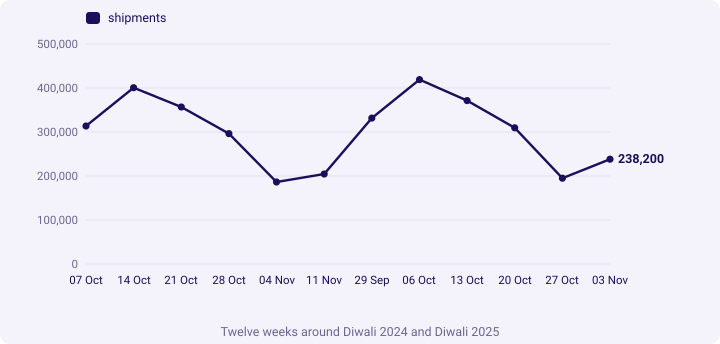

In [5]:
# A quick diagram of the shape.
kit.line(labels=[d.strftime("%d %b") for d in tw["week_start"]],
         series=[("shipments", tw["shipments"].tolist(), "lit")],
         title="Twelve weeks around Diwali 2024 and Diwali 2025", width=720)
kit.check("twelve rows carry 12 entries", len(tw) == 12)
kit.check("peak lands two weeks before each Diwali",
          peak["label"] in {"06 Oct 2025", "14 Oct 2024"})

## How do three simple rules forecast the Diwali 2025 week?

For the Diwali 2025 week (Mon 20 Oct 2025), three rules each give a forecast:

* **Naive.** Carry last week's actual forward: value from Mon 13 Oct 2025.
* **Same-week-last-year.** Copy the shipment 52 Mondays earlier: value from Mon
  21 Oct 2024.
* **Festival-aligned with drift.** Copy the week at the same offset from the
  previous Diwali week, and add one year of growth: value from Mon 28 Oct 2024
  (the 2024 Diwali week), multiplied by 1.04.

**Predict before you run.** Which forecast will land closest to the actual
shipment of 309,500?

a) Naive is closest.
b) Same-week-last-year is closest.
c) Festival-aligned with drift is closest.
d) All three land within 20,000 of actual.

In [6]:
# Pull the three source values from the twelve-row table.
s = twelve.set_index("week_start")["shipments"]

target_week = pd.Timestamp("2025-10-20")
actual = int(s.loc[target_week])

naive = int(s.loc[pd.Timestamp("2025-10-13")])
swly = int(s.loc[pd.Timestamp("2024-10-21")])
fa_source = int(s.loc[pd.Timestamp("2024-10-28")])
festival_aligned = round(fa_source * 1.04)

print(f"Actual (Mon 20 Oct 2025):            {actual:,}")
print(f"Naive = last week:                    {naive:,}  (miss {naive - actual:+,})")
print(f"Same-week-last-year = 52 Mon earlier: {swly:,}  (miss {swly - actual:+,})")
print(f"Festival-aligned (with 4% drift):     {festival_aligned:,}  (miss {festival_aligned - actual:+,})")

Actual (Mon 20 Oct 2025):            309,500
Naive = last week:                    371,400  (miss +61,900)
Same-week-last-year = 52 Mon earlier: 356,800  (miss +47,300)
Festival-aligned (with 4% drift):     308,256  (miss -1,244)


**What happened.** The answer is (c): festival-aligned with drift lands within
a thousand shipments; naive and same-week-last-year both over-forecast by about
50,000.

The reason sits in the week each rule copies from. Diwali 2024 fell on Mon 28 Oct
and Diwali 2025 on Mon 20 Oct: eight calendar days earlier. The naive copy reads
Mon 13 Oct 2025, which is one week before Diwali 2025 (ratio 1.7). The SWLY copy
reads Mon 21 Oct 2024, which is one week before Diwali 2024 (also ratio 1.7). Both
land on a 1.7 week while the target is a 1.4 week. The festival-aligned rule picks
the Mon-28-Oct-2024 week on purpose, because that was Diwali 2024's Monday, and
2025's Diwali Monday is Mon 20 Oct.

In [7]:
kit.check("festival-aligned lands within 2 percent of actual",
          abs(festival_aligned - actual) / actual < 0.02)
kit.check("naive over-forecasts by at least 50,000", naive - actual >= 50_000)
kit.check("SWLY over-forecasts by at least 40,000", swly - actual >= 40_000)

## A second route: compute the three forecasts straight from the ratios

A hurried analyst could reach the same three numbers from the shape of the series
rather than the twelve rows. For the Diwali 2025 week, 2025's shipments are growing
year-on-year at 4 percent, and a 1.4 week pattern on a baseline of 210,000 x 1.04
= 218,400 gives 305,760 shipments, within the noise of the actual 309,500.

In [8]:
baseline_2025 = 210_000 * 1.04
expected_1_4 = baseline_2025 * 1.4
print(f"Baseline 2025: {baseline_2025:,.0f}")
print(f"At ratio 1.4 (Diwali week): {expected_1_4:,.0f}  (actual {actual:,})")
kit.check("second route lands within 2 percent of actual",
          abs(expected_1_4 - actual) / actual < 0.02)

Baseline 2025: 218,400
At ratio 1.4 (Diwali week): 305,760  (actual 309,500)


## What the chapter earned, in one sentence

For a seasonal business whose festival moves, same-week-last-year and the naive
rule both read the shape at the wrong calendar position. Festival-aligned with
drift places the shape at the right offset from this year's festival and lands
close.

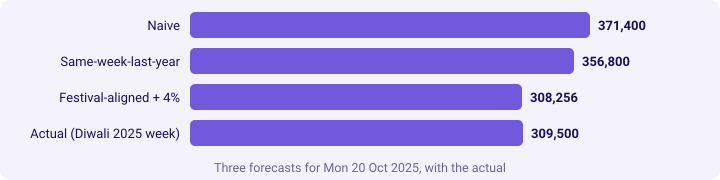

In [9]:
# SUM: the three forecasts drawn against the actual.
kit.bars([("Naive", naive), ("Same-week-last-year", swly),
          ("Festival-aligned + 4%", festival_aligned), ("Actual (Diwali 2025 week)", actual)],
         title="Three forecasts for Mon 20 Oct 2025, with the actual")
kit.check_summary()

Chapter 2 scores every method on 13 weeks the model has never seen.